# **BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding**

**Paper:** Devlin, J., Chang, M.-W., Lee, K., & Toutanova, K. .  
 **Main idea:** BERT learns word representations using context from both the left and right sides.




## **1. The paper and its research question**

**Research question in simple words:**  
How can a language model understand a word using the words around it, including words that appear before and after it?

**Why does this matter?**  
The same word can have different meanings in different sentences. A model needs context to understand which meaning is likely.

Real-life example: the word “bank”

- **Sentence A:** “I deposited money in the bank.”
- **Sentence B:** “I sat on the bank of the river.”

In Sentence A, *bank* means a financial institution. In Sentence B, it means the side of a river.

**Key point:** The word is the same, but its meaning depends on the context. BERT is designed to learn from context on both sides of a word.

## **2. What limitation did the paper address?**

Some earlier language models used a left-to-right or right-to-left language-modeling objective. A left-to-right model, for example, uses previous tokens when processing the next token, so it cannot use future words in the same way at that point.

The authors proposed **BERT (Bidirectional Encoder Representations from Transformers)** to learn deep bidirectional representations.

**Simple takeaway:** BERT learns from the left and right context together.

## **3. BERT Framework**

BERT uses two stages:

1. **Pre-tranining:** Learn general language patterns from large amounts of text.
2. **Fine-tuning:** Adapt the pretrained model to a specific task using task-specific examples.

For example, a pretrained model can be adapted for sentiment analysis, question answering, or language inference.



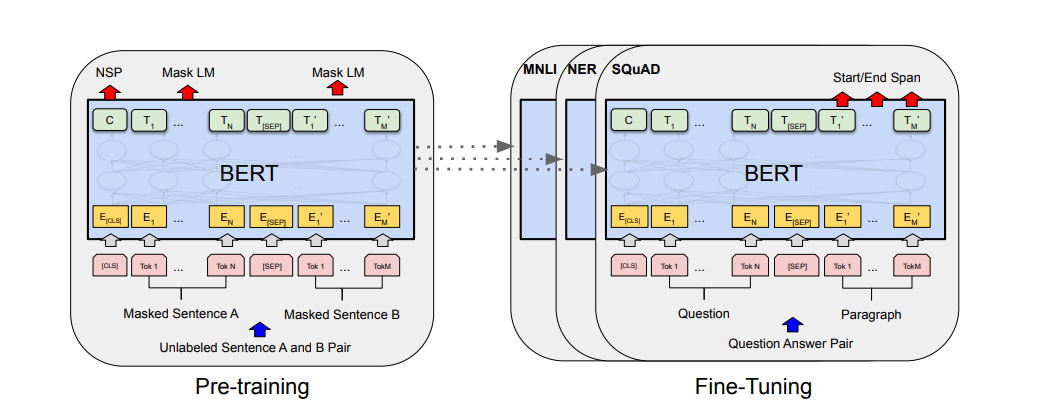

## **4. Pre-tranining BERT**

### **4.1 BERT was pre-train using two unsupervised tasks**

1. Masked Language Modeling (MLM)
2. Next Sentence Prediction (NSP)



### **4.1 Pre-train Tasks**

BERT was pre-train using two unsupervised tasks:

1. Masked Language Modeling (MLM)
2. Next Sentence Prediction (NSP)

#### Task1: Masked Language Modeling (MLM)

BERT hides selected tokens and learns to predict the original words using the surrounding context.

**Example:**

`I love [MASK] learning.`

The model tries to predict the missing token from the context.

In the original paper, 15% of token positions were selected for prediction. Of those selected positions, the original training procedure used `[MASK]` 80% of the time, a random token 10% of the time, and the unchanged token 10% of the time.

**Why is this useful?** It encourages the model to use context from both sides of a selected token.

#### Task 2: Next Sentence Prediction (NSP)

NSP gives BERT two text segments and asks whether Segment B actually follows Segment A in the original text.

**Example of a plausible pair:**
- A: “I went to the kitchen.”
- B: “I made a cup of coffee.”

During original pre-training, 50% of pairs were actual next-sentence pairs and 50% used a randomly selected sentence.

**Important detail:** The second sentence does not need to be grammatically wrong to be a negative example. It is labeled “NotNext” because it was not the actual next sentence in the source text.

#### MLM vs. NSP

| Task | What does BERT predict? | Main purpose |
|---|---|---|
| MLM | Selected missing or corrupted tokens | Learn word context |
| NSP | Whether B follows A in the original text | Learn sentence-pair relationships |

These are the two pre-training objectives used in the original BERT paper.

### **4.2 BERT Architecture**

The architecture of BERT is a multi-layer bidirectional Transformer encoder based on the original Transformer implementation

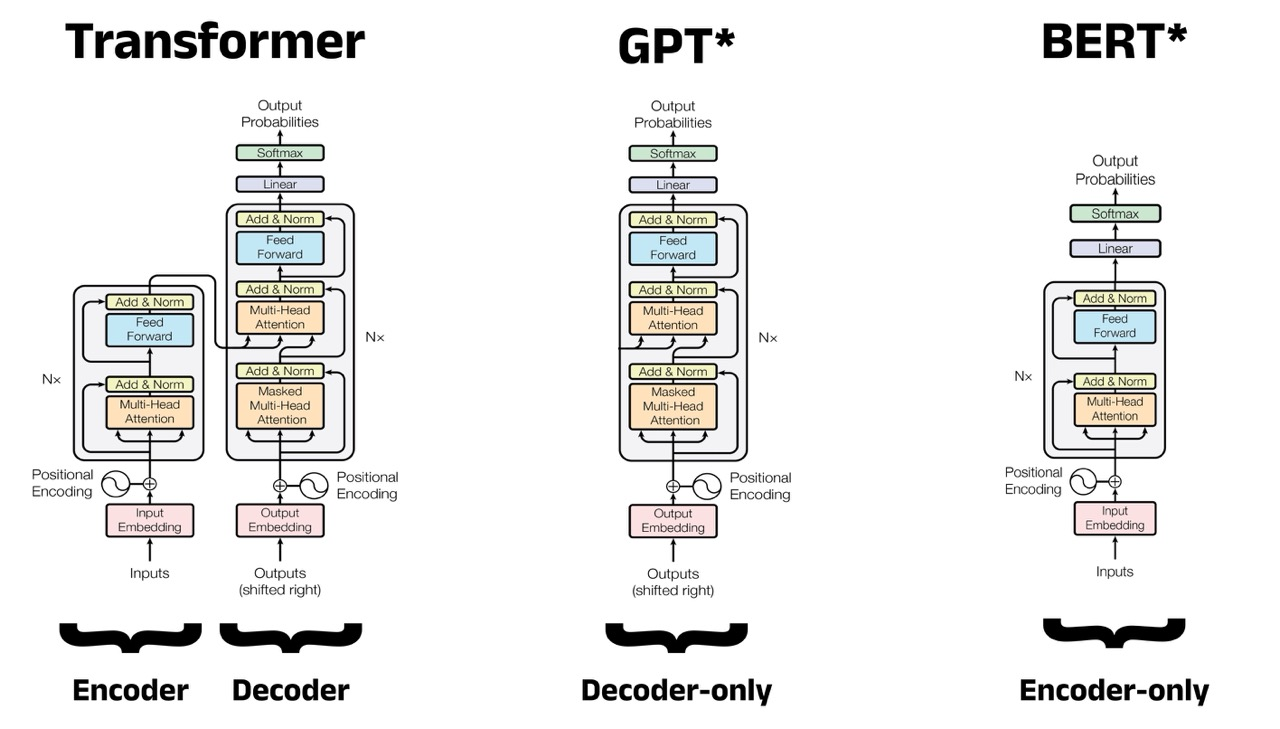

BERT uses the **Transformer encoder** and **self-attention**.

- **Transformer encoder:** the main network used to process the input tokens.
- **Self-attention:** helps each token use information from other tokens in the sequence.
- **Bidirectional:** BERT's attention can use context from both the left and right sides.

The model structure using three hyperparameters:

1. L: Number of layers (Transformer blocks)
2. H: Hidden size (the dimensionality of the hidden vectors)
3. A: Number of self-attention heads

The authors primarily evaluate two model sizes

* $\text{BERT}_{\text{BASE}}$
* $\text{BERT}_{\text{LARGE}}$


| Hyperparameter | \\(\text{BERT}_{\text{BASE}}\\) | \\(\text{BERT}_{\text{LARGE}}\\) |
| :--- | :--- | :--- |
| **Number of Transformer Layers (\\(L\\))** | 12 | 24 |
| **Hidden Size (\\(H\\))** | 768 | 1024 |
| **Self-Attention Heads (\\(A\\))** | 12 | 16 |
| **Total Parameters** | 110M | 340M |


* $\text{BERT}_{\text{BASE}}$ was designed to match the size of OpenAI GPT for direct comparison

### **4.3 Tokenizer**


The input representaion of the data

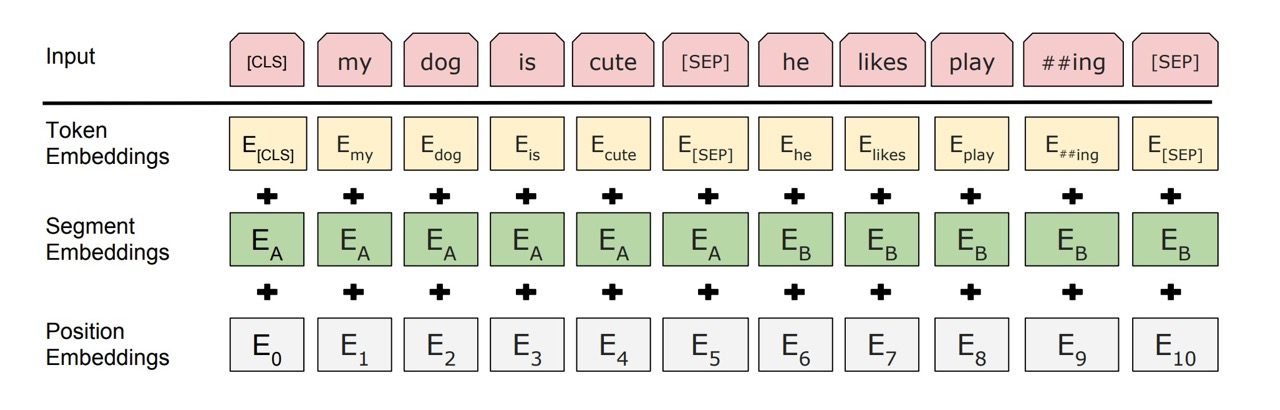

The input embedding process for BERT is made up of three stages:

- **Token embeddings:** represent the input tokens from WordPiece vocab. As with the original Transformer, the learned embedding for each token is then added to its positional and segment vectors to create the final embedding that will be passed to the self-attention mechanisms in BERT to add contextual information.


- **Segment embeddings:** indicate which segment a token belongs to when two segments are used.
Vectors encoding the segment that each token belongs to are also added. For the MLM pre-training task or any other non-NSP task (which feature only one [SEP]) token, all tokens in the input are considered to belong to segment A. For NSP tasks, all tokens after the second [SEP] are denoted as segment B.


- **Position embeddings:** give information about token positions.
Since the Transformer processes all words in parallel rather than in a sequential order like an RNN, it needs to know the position and order of each word in the sentence


The model adds these three kinds of embeddings to form the input representation.

### 4.4 Pre-training Data

BERT’s pre-training phase relies on a massive unlabeled text from 2 sourse:
- **BooksCorpus:** about 800 million words.
- **English Wikipedia:** about 2500 million words (2.5 billion).

These large text collections totaling approximately 3.3 billion words helped BERT learn general language patterns before fine-tuning on specific tasks.

**Why Document-Level Text Matters**

The data is document-level corpus (such as full books and Wikipedia articles) rather than a shuffled, sentence-level corpus. This to successfully enable it to process sequences of up to 512 tokens, the model must learn from long, contiguous spans of text that preserve logical sequence and thematic continuity across multiple sentences and paragraphs

## **5. Fine Tuning BERT**

Fine-tuning BERT is straightforward because its self-attention mechanism allows the same pre-trained model to be adapted to many downstream NLP tasks.

For each task, we provide the appropriate task-specific inputs and outputs and **fine-tune all BERT parameters end-to-end**.


So, Instead of training a new model from scratch for every task, we start with the **same pre-trained BERT** and adapt it to the specific task by **updating its parameters using task-specific data**.

In [ ]:
import torch
from transformers import BertTokenizer, BertForSequenceClassification
from torch.optim import AdamW

# 1. Load pre-trained BERT
tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")

model = BertForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    num_labels=2
)

# 2. Prepare the text
inputs = tokenizer(
    df["review_cleaned"].tolist(),
    padding=True,
    truncation=True,
    return_tensors="pt"
)

labels = torch.tensor(df["sentiment_encoded"].values)

# 3. Optimizer
optimizer = AdamW(model.parameters(), lr=2e-5)

# 4. Fine-tuning
model.train()

for epoch in range(4):

    outputs = model(
        input_ids=inputs["input_ids"],
        attention_mask=inputs["attention_mask"],
        labels=labels
    )

    loss = outputs.loss

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    print(f"Epoch {epoch + 1} | Loss: {loss.item():.4f}")

# Results: Comparing BERT with Previous Models

**Evaluation:** 11 NLP tasks across language understanding, reading comprehension, and commonsense reasoning.

### 1. GLUE — General Language Understanding

| Model | Average Score |
|---|---:|
| OpenAI GPT | 75.1 |
| BERTBASE | 79.6 |
| BERTLARGE | 82.1 |

### 2. SQuAD — Reading Comprehension

| Model | SQuAD 2.0 Test F1 |
|---|---:|
| Previous best single model | 78.0 |
| BERTLARGE | 83.1 |

### 3. SWAG — Commonsense Reasoning

| Model | Accuracy |
|---|---:|
| ESIM + ELMo | 59.2% |
| OpenAI GPT | 78.0% |
| BERTLARGE | 86.3% |

### Key Findings
- BERT outperformed the compared models on these reported benchmarks.
- BERTLARGE achieved stronger results than BERTBASE on GLUE.
- The results support the effectiveness of bidirectional pre-training across different NLP tasks.

## **7. Ablation Studies**

The authors conduct ablation experiments to investigate which components contribute most to BERT's performance.

**Research Questions**
- Does Next Sentence Prediction (NSP) improve performance?
- How important is bidirectional pre-training?
- Does increasing model size improve downstream results?

**Compared Configurations**
- BERTBASE: MLM + NSP
- No NSP: MLM only
- LTR & No NSP: Left-to-right language modeling
- LTR & No NSP + BiLSTM: Adds a BiLSTM during fine-tuning

The experiments compare these configurations on GLUE tasks and SQuAD.

### 7.1. Effect of Pre-training Objectives

| Model | MNLI-m | QNLI | MRPC | SQuAD F1 |
|---|---:|---:|---:|---:|
| BERTBASE | 84.4 | 88.4 | 86.7 | 88.5 |
| No NSP | 83.9 | 84.9 | 86.5 | 87.9 |
| LTR & No NSP | 82.1 | 84.3 | 77.5 | 77.8 |
| LTR & No NSP + BiLSTM | 82.1 | 84.1 | 75.7 | 84.9 |

**Key Findings**
- Removing NSP affects tasks differently, with a noticeable drop on QNLI.
- Replacing bidirectional MLM with left-to-right training substantially reduces MRPC and SQuAD performance.
- Adding BiLSTM improves SQuAD F1 from 77.8 to 84.9, but does not fully recover BERTBASE performance.

**Conclusion:** Bidirectional pre-training is particularly beneficial for tasks requiring contextual understanding.

### 7.2. Effect of Model Size

The authors investigate whether larger BERT models achieve better downstream performance.

| Model (L, H, A) | MNLI-m | MRPC | SST-2 |
|---|---:|---:|---:|
| (3, 768, 12) | 77.9 | 79.8 | 88.4 |
| (6, 768, 12) | 81.9 | 84.8 | 91.3 |
| (12, 768, 12) | 84.4 | 86.7 | 92.9 |
| (24, 1024, 16) | 86.6 | 87.8 | 93.7 |

*L: layers; H: hidden size; A: attention heads.*

**Finding:** Larger models generally achieve better results across these tasks, although they require more computational resources.

### 7.3. Feature-based vs. Fine-tuning

The authors compare two ways of applying pre-trained BERT to Named Entity Recognition (NER).

- **Fine-tuning:** Updates BERT's parameters for the target task.
- **Feature-based:** Uses BERT representations as input features without fine-tuning all its parameters.

| Approach | Dev F1 |
|---|---:|
| Fine-tuning BERTBASE | 96.4 |
| Last hidden layer | 94.9 |
| Concatenation of last four layers | 96.1 |

**Finding:** Combining the last four hidden layers achieves performance close to fine-tuning on this task, showing that BERT representations can be useful as features.

## **8. Limitation**



- **Computational cost:** Large BERT models require substantial training resources.
- **Data requirements:** Pre-training relies on large text corpora, which may not be available for every language or domain.
- **Fine-tuning stability:** The authors report that BERTLARGE can be sensitive to random initialization on small datasets.
- **Evaluation scope:** The reported benchmarks do not guarantee equal performance across all languages and domains.

**Overall:** BERT achieves strong results, but computational cost, data availability, and generalization remain important considerations.


## **9. Beyond BERT: Recent Developments**




BERT introduced an influential approach to Natural Language Processing (NLP) through deep bidirectional pre-training. However, research continued to improve encoder-based language models in terms of efficiency, context length, and multilingual capabilities.

### 1. ModernBERT (2024–2025)

ModernBERT is a modern encoder-only language model designed to improve efficiency, inference speed, and long-context processing. It supports sequences of up to 8,192 tokens, allowing it to handle longer texts than the original BERT models.

### 2. mmBERT (2025–2026)

mmBERT is a multilingual encoder model designed to extend language understanding across a much wider range of languages. It was trained on more than 1,800 languages, including many low-resource languages, helping expand the reach of encoder-based models beyond high-resource languages.

### Key Takeaway

BERT established an important foundation for bidirectional language understanding. Later models continued to build on this direction by improving efficiency, supporting longer contexts, and expanding multilingual coverage. These developments demonstrate how encoder-based models continue to evolve to meet different NLP needs.

## References

1. Devlin, J., Chang, M.-W., Lee, K., & Toutanova, K. (2019). **BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding.** Proceedings of NAACL-HLT 2019, pp. 4171–4186.  
   Paper: https://aclanthology.org/N19-1423/  
   DOI: https://doi.org/10.18653/v1/N19-1423

2. Hugging Face. **Transformers documentation: Pipelines.**  
   https://huggingface.co/docs/transformers/main_classes/pipelines

3. A Complete Guide to BERT with Code
 https://towardsdatascience.com/a-complete-guide-to-bert-with-code-9f87602e4a11/

4. Warner, B. et al. (2025). *Smarter, Better, Faster, Longer: A Modern Bidirectional Encoder for Fast, Memory Efficient, and Long Context Finetuning and Inference.* ACL 2025. https://aclanthology.org/2025.acl-long.127/

5. Marone, M. et al. (2026). *mmBERT: A Modern Multilingual Encoder with Annealed Language Learning.* ICML 2026. https://proceedings.mlr.press/v306/marone26a.html